### Load librairies and data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from nilearn.glm import threshold_stats_img
from nilearn.glm.first_level import FirstLevelModel
from nilearn.glm.first_level import make_first_level_design_matrix
from nilearn.image import mean_img
from nilearn.plotting import plot_stat_map
from nilearn.plotting import plot_design_matrix


data_dir = Path("../data") 

func_path = (
    data_dir / "fMRI" / "tfMRI_LANGUAGE_LR"
    / "tfMRI_LANGUAGE_LR.nii.gz"
)
events_path = (
    data_dir / "fMRI" / "tfMRI_LANGUAGE_LR" / "tfMRI_LANGUAGE_LR_task_onsets.csv"
)


In [2]:
events_raw = pd.read_csv(events_path)

print("Columns:", events_raw.columns.tolist())
display(events_raw.head(15))
print(events_raw.dtypes)

FileNotFoundError: [Errno 2] No such file or directory: '../data/fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR_task_onsets.csv'

In [36]:
# Keep only math and story as events
events = (
    events_raw.loc[
        events_raw["trial_type"].isin(["story", "math"]),
        ["onset", "duration", "trial_type"]
    ]
    .sort_values("onset")
    .reset_index(drop=True)
)

display(events)

,onset,duration,trial_type
0,0.241,28.270,story
1,30.095,12.241,math
2,42.570,12.312,math
3,56.524,27.147,story
4,85.206,12.667,math
5,98.120,12.542,math
6,112.274,26.070,story
7,139.930,11.844,math
8,152.045,12.528,math
9,164.853,9.838,math


In [37]:
img = nib.load(func_path)

TR = float(img.header.get_zooms()[3])
n_scans = img.shape[3]

# Create acquisition times
frame_times = np.arange(n_scans) * TR

TO CHECK: this assumes the first volume corresponds to time zero and no intial volumes have been removed

### a. Build experimental design matrix 

TODO Add explanation of the columns

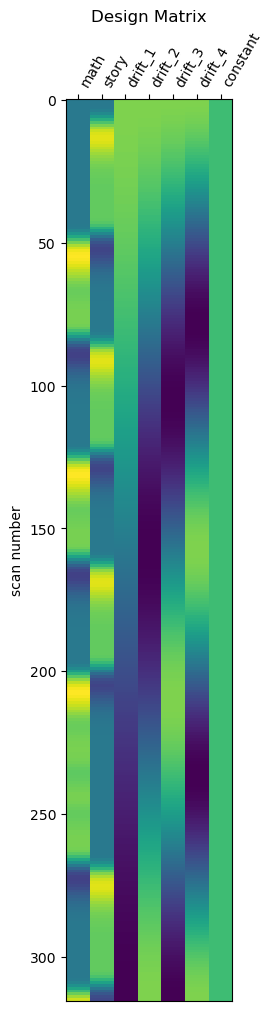

Matrix shape: (316, 7)
Columns: ['math', 'story', 'drift_1', 'drift_2', 'drift_3', 'drift_4', 'constant']


In [38]:
# Create design matrix
# Cutoff frequency of 0.01 Hz (100sec) gives 4 drift regressors  
design_matrix = make_first_level_design_matrix(
    frame_times=frame_times,
    events=events,
    hrf_model="glover",
    drift_model="cosine",
    high_pass=0.01,
)

plot_design_matrix(design_matrix)
plt.title("Design Matrix")
plt.show()

print("Matrix shape:", design_matrix.shape)
print("Columns:", design_matrix.columns.tolist())

### b. Compute and plot correlation matrix between regressors of the design matrix

TODO Add explanations

,math,story,drift_1,drift_2,drift_3,drift_4
math,1.00,-0.93,-0.08,-0.19,0.12,-0.34
story,-0.93,1.00,0.08,0.16,-0.10,0.30
drift_1,-0.08,0.08,1.00,-0.00,-0.00,-0.00
drift_2,-0.19,0.16,-0.00,1.00,-0.00,0.00
drift_3,0.12,-0.10,-0.00,-0.00,1.00,-0.00
drift_4,-0.34,0.30,-0.00,0.00,-0.00,1.00


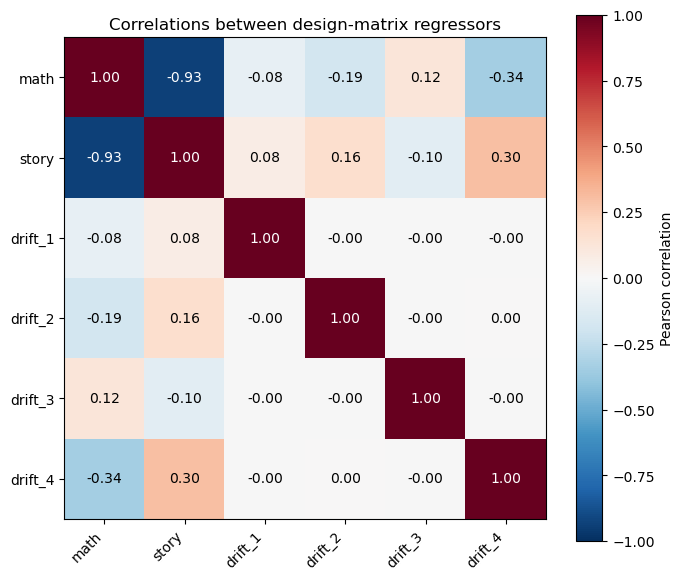

In [39]:
# Exclude the constant (its correlation is undefined)
regressors = design_matrix.drop(columns="constant")

# Compute correlations between columns
correlation = regressors.corr()

# Display the numerical values
display(correlation.round(2))

# Plot the correlation matrix
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)

names = correlation.columns
ax.set_xticks(range(len(names)), labels=names, rotation=45, ha="right")
ax.set_yticks(range(len(names)), labels=names)

for i in range(len(names)):
    for j in range(len(names)):
        ax.text(
            j, i, f"{correlation.iloc[i, j]:.2f}",
            ha="center", va="center",
            color="white" if abs(correlation.iloc[i, j]) > 0.6 else "black"
        )

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlations between design-matrix regressors")
plt.tight_layout()
plt.show()


"math" and "story" are close to -1 as they are negatively correlated. when the predicted story response is high, math is generally low.

There is some task-drift overlap especially with drift_4, but no very strong pairwise correlations.

Drift versus drift have zero correlation (expected). 


### c. Run GLM

We performed a first-level GLM on the single-subject run. A second-level analysis would be used to combine results across subjects and draw population-level conclusions.

In [40]:
# TODO: Replace with the actual filename once preprocessing is done
preprocessed_path = data_dir / "preprocessed_fmri.nii.gz"

In [41]:
#Check that the image and matrix have the same number of timepoints
preprocessed_img = nib.load(preprocessed_path)

print("fMRI volumes:", preprocessed_img.shape[3])
print("Design matrix rows:", len(design_matrix))

assert preprocessed_img.shape[3] == len(design_matrix)

FileNotFoundError: No such file or no access: '../data/preprocessed_fmri.nii.gz'

In [ ]:
# Fitting the GLM
# Single-subject, run-level analysis
# noise_model accounts for the fact that noise in neighbouring timepoints can be correlated
# No smoothing as preprocessing has handled it
glm = FirstLevelModel(
    t_r=TR,
    noise_model="ar1",
    smoothing_fwhm=None,
)

# Find weights for each column, at every voxel
glm.fit(
    preprocessed_img,
    design_matrices=design_matrix,
)

In [ ]:
# Compute contrasts
# Test whether the math weight differ from zero
# H0 : beta_math = 0
z_math = glm.compute_contrast(
    "math", stat_type="t", output_type="z_score"
)

# Test whether the story weight differ from zero
# H0 : beta_story = 0
z_story = glm.compute_contrast(
    "story", stat_type="t", output_type="z_score"
)

NameError: name 'glm' is not defined

In [42]:
# Display maps
background = mean_img(preprocessed_img)

#TODO check cluster_size, this is from the lab
fdr_rate = 0.05 
cluster_size = 10 

# Change threshold ?
for name, z_map in [("Math", z_math), ("Story", z_story)]:
    # Apply FDR correction and thresholding
    clean_map, threshold = threshold_stats_img(z_map, alpha=fdr_rate, height_control='fdr', cluster_threshold=cluster_size)

    # Plot results
    plot_stat_map(
        clean_map,
        bg_img=background,
        display_mode="z",
        cut_coords=5,
        threshold=threshold,
        title=f"{name}: FDR-corrected Z map (q < 0.05)",
    )

plt.show()

NameError: name 'preprocessed_img' is not defined

### d. Story vs math contrast and activation map

In [ ]:
# Test whether the story weight differ from the math weight
# H0 : beta_story - beta_math = 0
z_story_minus_math = glm.compute_contrast(
    "story - math",
    stat_type="t",
    output_type="z_score"
)

NameError: name 'glm' is not defined

In [ ]:
# Display maps
background = mean_img(preprocessed_img)

clean_map, threshold = threshold_stats_img(z_story_minus_math, alpha=fdr_rate, height_control='fdr')

plot_stat_map(
    clean_map,
    bg_img=background,
    display_mode="z",
    cut_coords=5,
    threshold=threshold,
    title="Story - Math: FDR q < 0.05",
)

plt.show()

Notes:

Main question: we choose 1 voxel and say "does the signal rise during story tasks, math tasks, or simply drift over time"


Design matrix :

Each column = one possible explanation

Each row = 1 acquired brain volume / 1 TR

math = Expected BOLD response to math tasks

drifts are included to account for changes unrelated to tasks



Initially, we had each event as 1 during the event, 0 outside of it. But as BOLD rises with a delay and falls off gradually, we need to transform it into smooth response by convolution with HRF

Bright periods = approx during the event

4 drifts: comes from nilearn function Ndrift = 2*T*fcutoff. fcutoof is 0.01 here (TODO say why?), T = Nscans * TR

--> design matrix contains possible explanatory patterns and fitting will use the measured fMRI signal to estimate the weight of every pattern at each voxel



constrasts answer "at which voxels is there evidence for a positive or negative task coefficient after accounting for the other columns"

TODO: enlever les trois premiers volumes, check threshold, check cut_coords!!!
cut_coords = 5 asks Nilearn to choose five axial slice positions. keep it constant between maps to compare them

if story_minus_math gives positive Z, it means story response > math response

threshold : decides which voxels remain visible on the map.
plot hides voxels with -thr < Z < thr and display thos with larger absolute Z-scores.
a z-score measures how strong the evidence for the constrast is, accounting for uncertainty. some voxels can exceed the threshold by chance, so the plot doesn't establish statistically significant activation.
use FDR correction at 0.05 to calculate threshold from results. it controls the expected proportion of false discoveries among the voxels declared signifcant at 5%